# 09 Paper-Ready Outputs

This notebook consolidates existing verified analysis outputs into paper-ready evidence tables, figures, captions and a manuscript scaffold.

It is for consolidation and presentation only. It does not run new simulations, resample Monte Carlo weights, alter analytical definitions, change priority thresholds, impute missing data, modify `data/raw`, or generate new exploratory findings.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 140)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-whitegrid')

NOTEBOOK_PATH = Path.cwd()
PROJECT_ROOT = NOTEBOOK_PATH if (NOTEBOOK_PATH / 'data').exists() else NOTEBOOK_PATH.parent
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures'
PAPER_DIR = PROJECT_ROOT / 'paper'
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
PAPER_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_FILES = {
    'baseline': PROJECT_ROOT / 'data' / 'processed' / 'dfsi_verified_baseline.csv',
    'verified_summary': TABLE_DIR / 'dfsi_verified_discrepancy_summary.csv',
    'verified_overlap': TABLE_DIR / 'dfsi_verified_top_group_overlap.csv',
    'verified_comparison': TABLE_DIR / 'dfsi_verified_comparison.csv',
    'component_summary': TABLE_DIR / 'dfsi_component_contribution_summary.csv',
    'loo_summary': TABLE_DIR / 'dfsi_leave_one_out_summary.csv',
    'fatality_summary': TABLE_DIR / 'fatality_exponent_summary.csv',
    'mc_summary': TABLE_DIR / 'dfsi_monte_carlo_scenario_summary.csv',
    'mc_district': TABLE_DIR / 'dfsi_monte_carlo_district_uncertainty.csv',
    'cutoff_summary': TABLE_DIR / 'dfsi_cutoff_sensitivity_summary.csv',
    'annual_completeness': TABLE_DIR / 'flood_inventory_annual_completeness.csv',
    'window_completeness': TABLE_DIR / 'flood_inventory_window_completeness.csv',
    'temporal_feasibility': TABLE_DIR / 'temporal_analysis_feasibility.csv',
    'weight_summary': TABLE_DIR / 'dfsi_monte_carlo_weight_summary.csv',
}
for name, path in SOURCE_FILES.items():
    assert path.exists(), f'Missing source file for {name}: {path}'

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

RAW_HASHES_BEFORE = {path.name: sha256_file(path) for path in sorted(RAW_DIR.glob('*.csv'))}

def rel(path):
    return str(Path(path).relative_to(PROJECT_ROOT))

baseline = pd.read_csv(SOURCE_FILES['baseline'])
verified_summary = pd.read_csv(SOURCE_FILES['verified_summary'])
verified_overlap = pd.read_csv(SOURCE_FILES['verified_overlap'])
verified_comparison = pd.read_csv(SOURCE_FILES['verified_comparison'])
component_summary = pd.read_csv(SOURCE_FILES['component_summary'])
loo_summary = pd.read_csv(SOURCE_FILES['loo_summary'])
fatality_summary = pd.read_csv(SOURCE_FILES['fatality_summary'])
mc_summary = pd.read_csv(SOURCE_FILES['mc_summary'])
mc_district = pd.read_csv(SOURCE_FILES['mc_district'])
cutoff_summary = pd.read_csv(SOURCE_FILES['cutoff_summary'])
annual_completeness = pd.read_csv(SOURCE_FILES['annual_completeness'])
window_completeness = pd.read_csv(SOURCE_FILES['window_completeness'])
temporal_feasibility = pd.read_csv(SOURCE_FILES['temporal_feasibility'])
weight_summary = pd.read_csv(SOURCE_FILES['weight_summary'])

complete_baseline = baseline.query("completeness_status == 'complete' and join_status == 'one_to_one_comparison_record'").copy()
assert len(complete_baseline) == 709
print(f'Loaded verified outputs from {PROJECT_ROOT}')

Loaded verified outputs from /Users/abhijithshaji/Documents/india-flood-index-robustness


## Results Evidence Audit

Every headline manuscript number is traced to a saved output file, source column and row/filter. The notebook does not type in values that cannot be read from an existing output.

In [2]:
claims = []

def add_claim(claim_id, section, claim, value, unit, source_key, source_column, source_filter, notes=''):
    claims.append({
        'claim_id': claim_id,
        'manuscript_section': section,
        'concise_claim': claim,
        'numerical_value': value,
        'unit_or_metric': unit,
        'source_file': rel(SOURCE_FILES[source_key]),
        'source_column': source_column,
        'source_row_or_filter': source_filter,
        'verification_status': 'verified',
        'notes': notes,
    })

def metric(metric_name):
    row = verified_summary.loc[verified_summary['metric'].eq(metric_name)]
    assert len(row) == 1, metric_name
    return row.iloc[0]['value']

def metric_float(metric_name):
    return float(metric(metric_name))

def metric_int(metric_name):
    return int(float(metric(metric_name)))

def overlap(group, column):
    row = verified_overlap.loc[verified_overlap['group'].eq(group)]
    assert len(row) == 1, group
    return row.iloc[0][column]

def component(component_name, column):
    row = component_summary.loc[component_summary['component'].eq(component_name)]
    assert len(row) == 1, component_name
    return row.iloc[0][column]

def loo(component_name, column):
    row = loo_summary.loc[loo_summary['removed_component'].eq(component_name)]
    assert len(row) == 1, component_name
    return row.iloc[0][column]

def fat(exp, column):
    row = fatality_summary.loc[np.isclose(fatality_summary['fatality_exponent'], exp)]
    assert len(row) == 1, exp
    return row.iloc[0][column]

def mc(scenario, column):
    row = mc_summary.loc[mc_summary['scenario'].eq(scenario)]
    assert len(row) == 1, scenario
    return row.iloc[0][column]

def cutoff(cutoff_name, column):
    row = cutoff_summary.loc[cutoff_summary['cutoff'].eq(cutoff_name)]
    assert len(row) == 1, cutoff_name
    return row.iloc[0][column]

def temporal(prefix):
    row = temporal_feasibility.loc[temporal_feasibility['component_or_question'].astype(str).str.startswith(prefix)]
    assert len(row) == 1, prefix
    return row.iloc[0]['period_specific_feasibility']

# Baseline and reproduction.
add_claim('R01','3.1 Reproduction','One-to-one baseline rows',metric_int('one_to_one_comparison_rows'),'records','verified_summary','value',"metric == 'one_to_one_comparison_rows'")
add_claim('R02','3.1 Reproduction','Complete comparison records',metric_int('complete_comparison_rows'),'records','verified_summary','value',"metric == 'complete_comparison_rows'")
add_claim('R03','3.1 Reproduction','Incomplete records preserved without imputation',metric_int('incomplete_records_preserved'),'records','verified_summary','value',"metric == 'incomplete_records_preserved'")
add_claim('R04','3.1 Reproduction','Reproduction Spearman correlation',metric_float('spearman_correlation'),'Spearman rho','verified_summary','value',"metric == 'spearman_correlation'")
add_claim('R05','3.1 Reproduction','Reproduction Pearson correlation',metric_float('pearson_correlation'),'Pearson r','verified_summary','value',"metric == 'pearson_correlation'")
add_claim('R06','3.1 Reproduction','Median absolute numerical difference',metric_float('median_absolute_numerical_difference'),'DFSI score units','verified_summary','value',"metric == 'median_absolute_numerical_difference'")
add_claim('R07','3.1 Reproduction','Median absolute rank difference',metric_float('median_absolute_rank_difference'),'rank positions','verified_summary','value',"metric == 'median_absolute_rank_difference'")
add_claim('R08','3.1 Reproduction','Maximum absolute rank difference',metric_float('maximum_absolute_rank_difference'),'rank positions','verified_summary','value',"metric == 'maximum_absolute_rank_difference'")
add_claim('R09','3.1 Reproduction','Reconstructed DFSI minimum',float(complete_baseline['reconstructed_dfsi'].min()),'DFSI score','baseline','reconstructed_dfsi',"complete and one_to_one_comparison_record")
add_claim('R10','3.1 Reproduction','Reconstructed DFSI maximum',float(complete_baseline['reconstructed_dfsi'].max()),'DFSI score','baseline','reconstructed_dfsi',"complete and one_to_one_comparison_record")
add_claim('R11','3.1 Reproduction','Published DFSI minimum among complete records',float(complete_baseline['published_dfsi'].min()),'DFSI score','baseline','published_dfsi',"complete and one_to_one_comparison_record")
add_claim('R12','3.1 Reproduction','Published DFSI maximum among complete records',float(complete_baseline['published_dfsi'].max()),'DFSI score','baseline','published_dfsi',"complete and one_to_one_comparison_record")
for i, group in enumerate(['top_25_districts','top_50_districts','top_10_percent','top_100_districts'], start=13):
    add_claim(f'R{i:02d}','3.1 Reproduction',f'Published-versus-reconstructed overlap for {group}',int(overlap(group,'overlap_count')),'districts','verified_overlap','overlap_count',f"group == '{group}'",f"Out of {int(overlap(group,'n_requested'))}.")

# Component contribution and leave-one-out.
for i, comp in enumerate(component_summary['component'].tolist(), start=1):
    add_claim(f'C{i:02d}','3.2 Component influence',f'Median numerical contribution: {comp}',float(component(comp,'median_percentage_contribution_to_total_dfsi')),'percent','component_summary','median_percentage_contribution_to_total_dfsi',f"component == '{comp}'",'Descriptive numerical contribution, not causal importance.')
add_claim('L01','3.2 Component influence','Fatalities removal median absolute rank change',float(loo('fatalities','median_absolute_rank_change')),'rank positions','loo_summary','median_absolute_rank_change',"removed_component == 'fatalities'")
add_claim('L02','3.2 Component influence','Fatalities removal maximum absolute rank change',float(loo('fatalities','maximum_absolute_rank_change')),'rank positions','loo_summary','maximum_absolute_rank_change',"removed_component == 'fatalities'")
add_claim('L03','3.2 Component influence','Injured-people removal top-10% entries',int(loo('injured_people','districts_entering_top_10_percent_count')),'districts','loo_summary','districts_entering_top_10_percent_count',"removed_component == 'injured_people'")
add_claim('L04','3.2 Component influence','Injured-people removal top-10% exits',int(loo('injured_people','districts_leaving_top_10_percent_count')),'districts','loo_summary','districts_leaving_top_10_percent_count',"removed_component == 'injured_people'")
add_claim('L05','3.2 Component influence','Minimum leave-one-out Spearman correlation',float(loo_summary['spearman_correlation_with_complete_baseline_index'].min()),'Spearman rho','loo_summary','spearman_correlation_with_complete_baseline_index','minimum across all leave-one-out variants')
for comp_name in loo_summary['removed_component']:
    add_claim(f'L_{comp_name}_rho','3.2 Component influence',f'Leave-one-out Spearman without {comp_name}',float(loo(comp_name,'spearman_correlation_with_complete_baseline_index')),'Spearman rho','loo_summary','spearman_correlation_with_complete_baseline_index',f"removed_component == '{comp_name}'")
    add_claim(f'L_{comp_name}_median','3.2 Component influence',f'Leave-one-out median rank change without {comp_name}',float(loo(comp_name,'median_absolute_rank_change')),'rank positions','loo_summary','median_absolute_rank_change',f"removed_component == '{comp_name}'")

# Fatality exponent.
for exp in [1.0,1.5,2.0,2.5,3.0]:
    exp_id = str(exp).replace('.','_')
    add_claim(f'F{exp_id}_rho','3.2 Fatality-exponent sensitivity',f'Fatality exponent {exp} Spearman',float(fat(exp,'spearman_correlation_with_exponent_2_baseline')),'Spearman rho','fatality_summary','spearman_correlation_with_exponent_2_baseline',f'fatality_exponent == {exp}')
    add_claim(f'F{exp_id}_median','3.2 Fatality-exponent sensitivity',f'Fatality exponent {exp} median rank change',float(fat(exp,'median_absolute_rank_change')),'rank positions','fatality_summary','median_absolute_rank_change',f'fatality_exponent == {exp}')
    add_claim(f'F{exp_id}_max','3.2 Fatality-exponent sensitivity',f'Fatality exponent {exp} maximum rank change',int(fat(exp,'maximum_rank_change')),'rank positions','fatality_summary','maximum_rank_change',f'fatality_exponent == {exp}')
    add_claim(f'F{exp_id}_top10','3.2 Fatality-exponent sensitivity',f'Fatality exponent {exp} top-10% overlap',int(fat(exp,'top_10_percent_overlap_count')),'districts','fatality_summary','top_10_percent_overlap_count',f'fatality_exponent == {exp}',f"Out of {int(fat(exp,'top_10_percent_n'))}.")

# Monte Carlo.
for scenario in ['narrow','moderate','wide']:
    add_claim(f'MC_{scenario}_rho','3.3 Monte Carlo uncertainty',f'{scenario} scenario median Spearman',float(mc(scenario,'median_spearman_correlation_with_baseline_rank')),'Spearman rho','mc_summary','median_spearman_correlation_with_baseline_rank',f"scenario == '{scenario}'")
    add_claim(f'MC_{scenario}_p05','3.3 Monte Carlo uncertainty',f'{scenario} scenario Spearman 5th percentile',float(mc(scenario,'spearman_correlation_p05')),'Spearman rho','mc_summary','spearman_correlation_p05',f"scenario == '{scenario}'")
    add_claim(f'MC_{scenario}_p95','3.3 Monte Carlo uncertainty',f'{scenario} scenario Spearman 95th percentile',float(mc(scenario,'spearman_correlation_p95')),'Spearman rho','mc_summary','spearman_correlation_p95',f"scenario == '{scenario}'")
    add_claim(f'MC_{scenario}_overlap','3.3 Monte Carlo uncertainty',f'{scenario} scenario mean top-10% overlap',float(mc(scenario,'mean_top10_overlap_with_baseline')),'districts','mc_summary','mean_top10_overlap_with_baseline',f"scenario == '{scenario}'")
    add_claim(f'MC_{scenario}_robust','3.3 Monte Carlo uncertainty',f'{scenario} scenario robust high-priority districts',int(mc(scenario,'robust_high_priority_districts')),'districts','mc_summary','robust_high_priority_districts',f"scenario == '{scenario}'")
    add_claim(f'MC_{scenario}_sensitive','3.3 Monte Carlo uncertainty',f'{scenario} scenario weight-sensitive districts',int(mc(scenario,'weight_sensitive_priority_districts')),'districts','mc_summary','weight_sensitive_priority_districts',f"scenario == '{scenario}'")
mod = mc_district.query("scenario == 'moderate'").copy()
add_claim('MC01','3.3 Monte Carlo uncertainty','Moderate scenario simulations',int(mc('moderate','simulations')),'simulations','mc_summary','simulations',"scenario == 'moderate'")
add_claim('MC02','3.3 Monte Carlo uncertainty','Moderate scenario concentration parameter',float(mc('moderate','concentration')),'Dirichlet concentration','mc_summary','concentration',"scenario == 'moderate'")
add_claim('MC03','3.3 Monte Carlo uncertainty','Baseline top-10% districts below 0.80 probability',int((mod['baseline_top10'] & mod['top10_probability'].lt(0.80)).sum()),'districts','mc_district','baseline_top10; top10_probability',"scenario == 'moderate' and baseline_top10 and top10_probability < 0.80")
add_claim('MC04','3.3 Monte Carlo uncertainty','Moderate scenario usually-outside districts',int(mod['top10_probability'].le(0.20).sum()),'districts','mc_district','top10_probability',"scenario == 'moderate' and top10_probability <= 0.20")

# Cutoff sensitivity.
for c in ['top_5pct','top_10pct','top_15pct','top_20pct','top_25pct']:
    add_claim(f'P_{c}_count','3.4 Cutoff sensitivity',f'{c} fixed district count',int(cutoff(c,'cutoff_count')),'districts','cutoff_summary','cutoff_count',f"cutoff == '{c}'")
    add_claim(f'P_{c}_robust_share','3.4 Cutoff sensitivity',f'{c} robust baseline-priority proportion',float(cutoff(c,'baseline_priority_robust_proportion')),'proportion','cutoff_summary','baseline_priority_robust_proportion',f"cutoff == '{c}'")
    add_claim(f'P_{c}_sensitive','3.4 Cutoff sensitivity',f'{c} weight-sensitive districts',int(cutoff(c,'cutoff_sensitive_districts')),'districts','cutoff_summary','cutoff_sensitive_districts',f"cutoff == '{c}'")
    add_claim(f'P_{c}_below80','3.4 Cutoff sensitivity',f'{c} baseline priority districts below 0.80',int(cutoff(c,'baseline_members_below_0_80_probability')),'districts','cutoff_summary','baseline_members_below_0_80_probability',f"cutoff == '{c}'")
add_claim('P01','3.4 Cutoff sensitivity','Largest number of weight-sensitive districts across cutoffs',int(cutoff_summary['cutoff_sensitive_districts'].max()),'districts','cutoff_summary','cutoff_sensitive_districts','maximum across all cutoffs')
add_claim('P02','3.4 Cutoff sensitivity','Cutoffs with nonzero priority instability',int((cutoff_summary['cutoff_sensitive_districts'] > 0).sum()),'cutoffs','cutoff_summary','cutoff_sensitive_districts','cutoff_sensitive_districts > 0')

# Reporting completeness.
add_claim('T01','3.5 Temporal limitations','Inventory audit start year',int(window_completeness['start_year'].min()),'year','window_completeness','start_year','minimum across windows')
add_claim('T02','3.5 Temporal limitations','Inventory audit end year',int(window_completeness['end_year'].max()),'year','window_completeness','end_year','maximum across windows')
add_claim('T03','3.5 Temporal limitations','Reporting volume changed substantially over time',temporal('A.'),'feasibility answer','temporal_feasibility','period_specific_feasibility',"component_or_question starts with 'A.'")
add_claim('T04','3.5 Temporal limitations','Reporting completeness changed substantially over time',temporal('B.'),'feasibility answer','temporal_feasibility','period_specific_feasibility',"component_or_question starts with 'B.'")
add_claim('T05','3.5 Temporal limitations','Complete period-specific DFSI can be reconstructed',temporal('E.'),'feasibility answer','temporal_feasibility','period_specific_feasibility',"component_or_question starts with 'E.'")
add_claim('T06','3.5 Temporal limitations','Event-derived temporal sensitivity feasibility',temporal('F.'),'feasibility answer','temporal_feasibility','period_specific_feasibility',"component_or_question starts with 'F.'")
for _, row in window_completeness.iterrows():
    add_claim(f"T_window_{row['window']}",'3.5 Temporal limitations',f"{row['window']} recorded events",int(row['total_recorded_events']),'recorded events','window_completeness','total_recorded_events',f"window == '{row['window']}'",'Reporting volume, not physical flood frequency.')

claims_audit = pd.DataFrame(claims)
assert claims_audit['claim_id'].is_unique
assert not claims_audit['numerical_value'].isna().any()
claims_audit.to_csv(PAPER_DIR / 'results_claims_audit.csv', index=False)
print(f'Wrote {rel(PAPER_DIR / "results_claims_audit.csv")} with {len(claims_audit)} claims')
display(claims_audit.head(15))

Wrote paper/results_claims_audit.csv with 112 claims


,claim_id,manuscript_section,concise_claim,numerical_value,unit_or_metric,source_file,source_column,source_row_or_filter,verification_status,notes
0,R01,3.1 Reproduction,One-to-one baseline rows,720,records,outputs/tables/dfsi_verified_discrepancy_summa...,value,metric == 'one_to_one_comparison_rows',verified,
1,R02,3.1 Reproduction,Complete comparison records,709,records,outputs/tables/dfsi_verified_discrepancy_summa...,value,metric == 'complete_comparison_rows',verified,
2,R03,3.1 Reproduction,Incomplete records preserved without imputation,11,records,outputs/tables/dfsi_verified_discrepancy_summa...,value,metric == 'incomplete_records_preserved',verified,
3,R04,3.1 Reproduction,Reproduction Spearman correlation,0.958847,Spearman rho,outputs/tables/dfsi_verified_discrepancy_summa...,value,metric == 'spearman_correlation',verified,
4,R05,3.1 Reproduction,Reproduction Pearson correlation,0.958716,Pearson r,outputs/tables/dfsi_verified_discrepancy_summa...,value,metric == 'pearson_correlation',verified,
5,R06,3.1 Reproduction,Median absolute numerical difference,1.206769,DFSI score units,outputs/tables/dfsi_verified_discrepancy_summa...,value,metric == 'median_absolute_numerical_difference',verified,
6,R07,3.1 Reproduction,Median absolute rank difference,18.0,rank positions,outputs/tables/dfsi_verified_discrepancy_summa...,value,metric == 'median_absolute_rank_difference',verified,
7,R08,3.1 Reproduction,Maximum absolute rank difference,345.0,rank positions,outputs/tables/dfsi_verified_discrepancy_summa...,value,metric == 'maximum_absolute_rank_difference',verified,
8,R09,3.1 Reproduction,Reconstructed DFSI minimum,5.672769,DFSI score,data/processed/dfsi_verified_baseline.csv,reconstructed_dfsi,complete and one_to_one_comparison_record,verified,
9,R10,3.1 Reproduction,Reconstructed DFSI maximum,17.948685,DFSI score,data/processed/dfsi_verified_baseline.csv,reconstructed_dfsi,complete and one_to_one_comparison_record,verified,


## Headline Claim Validation

In [3]:
lookup = claims_audit.set_index('claim_id')['numerical_value'].to_dict()
assert int(lookup['R01']) == 720
assert int(lookup['R02']) == 709
assert int(lookup['R03']) == 11
assert np.isclose(float(lookup['R04']), 0.9588466131829585)
assert np.isclose(float(lookup['R05']), 0.9587155873101515)
assert np.isclose(float(lookup['R06']), 1.2067694216134761)
assert np.isclose(float(lookup['R07']), 18.0)
assert np.isclose(float(lookup['R08']), 345.0)
assert int(lookup['MC_moderate_robust']) == 43
assert int(lookup['MC_moderate_sensitive']) == 56
assert int(lookup['MC03']) == 28
assert np.isclose(float(lookup['MC_moderate_rho']), 0.9877680684599932)
assert int(lookup['P01']) == 56
assert int(lookup['P02']) == 5
assert str(lookup['T05']).lower() == 'no'
print('Headline claims match existing source CSV files.')

Headline claims match existing source CSV files.


## Main Paper Tables

In [4]:
table1_rows = [
    ['sample','one_to_one_baseline_rows',metric_int('one_to_one_comparison_rows'),'records','R01'],
    ['sample','complete_comparison_records',metric_int('complete_comparison_rows'),'records','R02'],
    ['sample','incomplete_records_preserved',metric_int('incomplete_records_preserved'),'records','R03'],
    ['range','published_dfsi_min_complete',complete_baseline['published_dfsi'].min(),'DFSI score','R11'],
    ['range','published_dfsi_max_complete',complete_baseline['published_dfsi'].max(),'DFSI score','R12'],
    ['range','reconstructed_dfsi_min_complete',complete_baseline['reconstructed_dfsi'].min(),'DFSI score','R09'],
    ['range','reconstructed_dfsi_max_complete',complete_baseline['reconstructed_dfsi'].max(),'DFSI score','R10'],
    ['correlation','pearson_correlation',metric_float('pearson_correlation'),'Pearson r','R05'],
    ['correlation','spearman_correlation',metric_float('spearman_correlation'),'Spearman rho','R04'],
    ['difference','median_absolute_numerical_difference',metric_float('median_absolute_numerical_difference'),'DFSI score units','R06'],
    ['difference','median_absolute_rank_difference',metric_float('median_absolute_rank_difference'),'rank positions','R07'],
    ['difference','maximum_absolute_rank_difference',metric_float('maximum_absolute_rank_difference'),'rank positions','R08'],
]
for group in ['top_25_districts','top_50_districts','top_10_percent','top_100_districts']:
    table1_rows.append(['priority_overlap',f'{group}_overlap_count',int(overlap(group,'overlap_count')),f"districts out of {int(overlap(group,'n_requested'))}",claims_audit.loc[claims_audit['concise_claim'].eq(f'Published-versus-reconstructed overlap for {group}'),'claim_id'].iloc[0]])
table1 = pd.DataFrame(table1_rows, columns=['category','metric','value','unit','source_claim_id'])
table1.to_csv(PAPER_DIR / 'table_1_reproduction_summary.csv', index=False)

component_part = component_summary[['component','median_percentage_contribution_to_total_dfsi']].rename(columns={'component':'item','median_percentage_contribution_to_total_dfsi':'component_median_contribution_percent'})
component_part['analysis_type'] = 'component_contribution'
loo_part = loo_summary[['removed_component','spearman_correlation_with_complete_baseline_index','median_absolute_rank_change','maximum_absolute_rank_change','districts_entering_top_10_percent_count','districts_leaving_top_10_percent_count']].rename(columns={'removed_component':'item','spearman_correlation_with_complete_baseline_index':'leave_one_out_spearman','districts_entering_top_10_percent_count':'top10_entries','districts_leaving_top_10_percent_count':'top10_exits'})
loo_part['analysis_type'] = 'leave_one_component_out'
fatality_part = fatality_summary[['fatality_exponent','spearman_correlation_with_exponent_2_baseline','median_absolute_rank_change','maximum_rank_change','top_10_percent_overlap_count','districts_entering_top_10_percent_count','districts_leaving_top_10_percent_count']].copy()
fatality_part['item'] = 'fatality_exponent_' + fatality_part['fatality_exponent'].astype(str)
fatality_part = fatality_part.rename(columns={'spearman_correlation_with_exponent_2_baseline':'fatality_exponent_spearman','maximum_rank_change':'maximum_absolute_rank_change','districts_entering_top_10_percent_count':'top10_entries','districts_leaving_top_10_percent_count':'top10_exits'})
fatality_part['analysis_type'] = 'fatality_exponent_sensitivity'
table2_cols = ['analysis_type','item','component_median_contribution_percent','leave_one_out_spearman','fatality_exponent_spearman','median_absolute_rank_change','maximum_absolute_rank_change','top_10_percent_overlap_count','top10_entries','top10_exits']
table2 = pd.concat([component_part, loo_part, fatality_part], ignore_index=True)
for col in table2_cols:
    if col not in table2.columns:
        table2[col] = np.nan
table2 = table2[table2_cols]
table2.to_csv(PAPER_DIR / 'table_2_component_and_weight_sensitivity.csv', index=False)

mc_part = mc_summary.copy()
mc_part['analysis_type'] = 'monte_carlo_weight_uncertainty'
mc_part['item'] = mc_part['scenario']
mc_part = mc_part.rename(columns={'mean_top10_overlap_with_baseline':'mean_overlap_with_baseline','minimum_top10_overlap_with_baseline':'minimum_overlap_with_baseline','maximum_top10_overlap_with_baseline':'maximum_overlap_with_baseline','median_districts_entering_leaving_baseline_top10':'median_entering_leaving','robust_high_priority_districts':'robust_priority_districts','weight_sensitive_priority_districts':'sensitive_priority_districts'})
cut_part = cutoff_summary.copy()
cut_part['analysis_type'] = 'priority_cutoff_sensitivity'
cut_part['item'] = cut_part['cutoff']
cut_part = cut_part.rename(columns={'mean_simulated_overlap_with_baseline':'mean_overlap_with_baseline','minimum_simulated_overlap_with_baseline':'minimum_overlap_with_baseline','maximum_simulated_overlap_with_baseline':'maximum_overlap_with_baseline','median_number_entering_baseline_priority_group':'median_entering_leaving','robust_priority_districts':'robust_priority_districts','cutoff_sensitive_districts':'sensitive_priority_districts'})
table3_cols = ['analysis_type','item','concentration','simulations','district_count','cutoff_count','median_spearman_correlation_with_baseline_rank','spearman_correlation_p05','spearman_correlation_p95','mean_overlap_with_baseline','minimum_overlap_with_baseline','maximum_overlap_with_baseline','median_entering_leaving','robust_priority_districts','sensitive_priority_districts','baseline_members_below_0_80_probability','baseline_priority_robust_proportion']
table3 = pd.concat([mc_part, cut_part], ignore_index=True)
for col in table3_cols:
    if col not in table3.columns:
        table3[col] = np.nan
table3 = table3[table3_cols]
table3.to_csv(PAPER_DIR / 'table_3_monte_carlo_and_cutoff_summary.csv', index=False)

display(table1)
display(table2.head(12))
display(table3)

,category,metric,value,unit,source_claim_id
0,sample,one_to_one_baseline_rows,720.000000,records,R01
1,sample,complete_comparison_records,709.000000,records,R02
2,sample,incomplete_records_preserved,11.000000,records,R03
3,range,published_dfsi_min_complete,4.244485,DFSI score,R11
4,range,published_dfsi_max_complete,19.300564,DFSI score,R12
5,range,reconstructed_dfsi_min_complete,5.672769,DFSI score,R09
6,range,reconstructed_dfsi_max_complete,17.948685,DFSI score,R10
7,correlation,pearson_correlation,0.958716,Pearson r,R05
8,correlation,spearman_correlation,0.958847,Spearman rho,R04
9,difference,median_absolute_numerical_difference,1.206769,DFSI score units,R06


,analysis_type,item,component_median_contribution_percent,leave_one_out_spearman,fatality_exponent_spearman,median_absolute_rank_change,maximum_absolute_rank_change,top_10_percent_overlap_count,top10_entries,top10_exits
0,component_contribution,flood_events,10.721350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,component_contribution,mean_duration,7.714917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,component_contribution,fatalities,26.144410,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,component_contribution,injured_people,4.496081,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,component_contribution,flooded_area,3.018811,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,component_contribution,population,47.839248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,leave_one_component_out,flood_events,NaN,0.979279,NaN,16.0,180.0,NaN,13.0,13.0
7,leave_one_component_out,mean_duration,NaN,0.992934,NaN,16.0,69.0,NaN,12.0,12.0
8,leave_one_component_out,fatalities,NaN,0.945272,NaN,37.0,383.0,NaN,14.0,14.0
9,leave_one_component_out,injured_people,NaN,0.971964,NaN,25.0,214.0,NaN,19.0,19.0


,analysis_type,item,concentration,simulations,district_count,cutoff_count,median_spearman_correlation_with_baseline_rank,spearman_correlation_p05,spearman_correlation_p95,mean_overlap_with_baseline,minimum_overlap_with_baseline,maximum_overlap_with_baseline,median_entering_leaving,robust_priority_districts,sensitive_priority_districts,baseline_members_below_0_80_probability,baseline_priority_robust_proportion
0,monte_carlo_weight_uncertainty,narrow,100.0,10000.0,709.0,NaN,0.995934,0.988190,0.998923,63.6137,46,71,7.0,54.0,33.0,NaN,NaN
1,monte_carlo_weight_uncertainty,moderate,30.0,10000.0,709.0,NaN,0.987768,0.963424,0.996597,58.9362,37,70,11.0,43.0,56.0,NaN,NaN
2,monte_carlo_weight_uncertainty,wide,10.0,10000.0,709.0,NaN,0.968132,0.900572,0.990891,52.8193,27,69,17.0,32.0,82.0,NaN,NaN
3,priority_cutoff_sensitivity,top_5pct,NaN,NaN,NaN,36.0,NaN,NaN,NaN,28.3196,14,36,7.0,21.0,30.0,15.0,0.583333
4,priority_cutoff_sensitivity,top_10pct,NaN,NaN,NaN,71.0,NaN,NaN,NaN,58.9362,37,70,11.0,43.0,56.0,28.0,0.605634
5,priority_cutoff_sensitivity,top_15pct,NaN,NaN,NaN,106.0,NaN,NaN,NaN,93.3304,62,105,12.0,79.0,56.0,27.0,0.745283
6,priority_cutoff_sensitivity,top_20pct,NaN,NaN,NaN,142.0,NaN,NaN,NaN,128.5741,89,142,12.0,116.0,56.0,26.0,0.816901
7,priority_cutoff_sensitivity,top_25pct,NaN,NaN,NaN,177.0,NaN,NaN,NaN,162.8482,117,176,13.0,148.0,56.0,29.0,0.836158


## Main Paper Figures

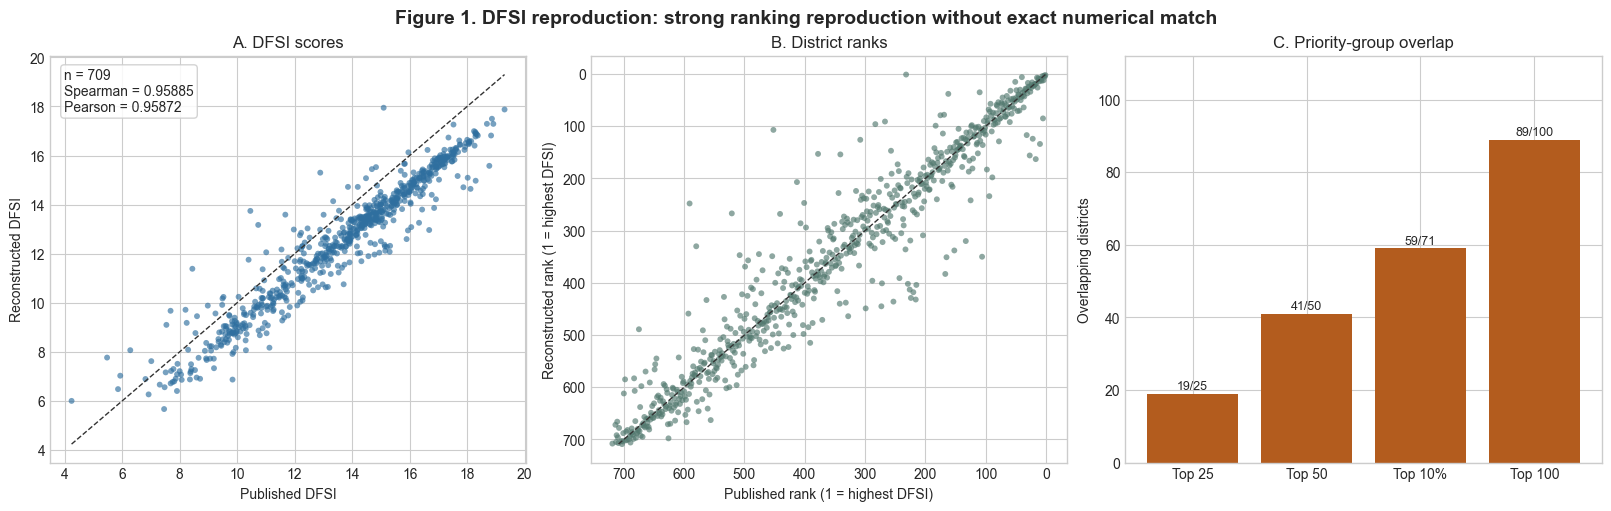

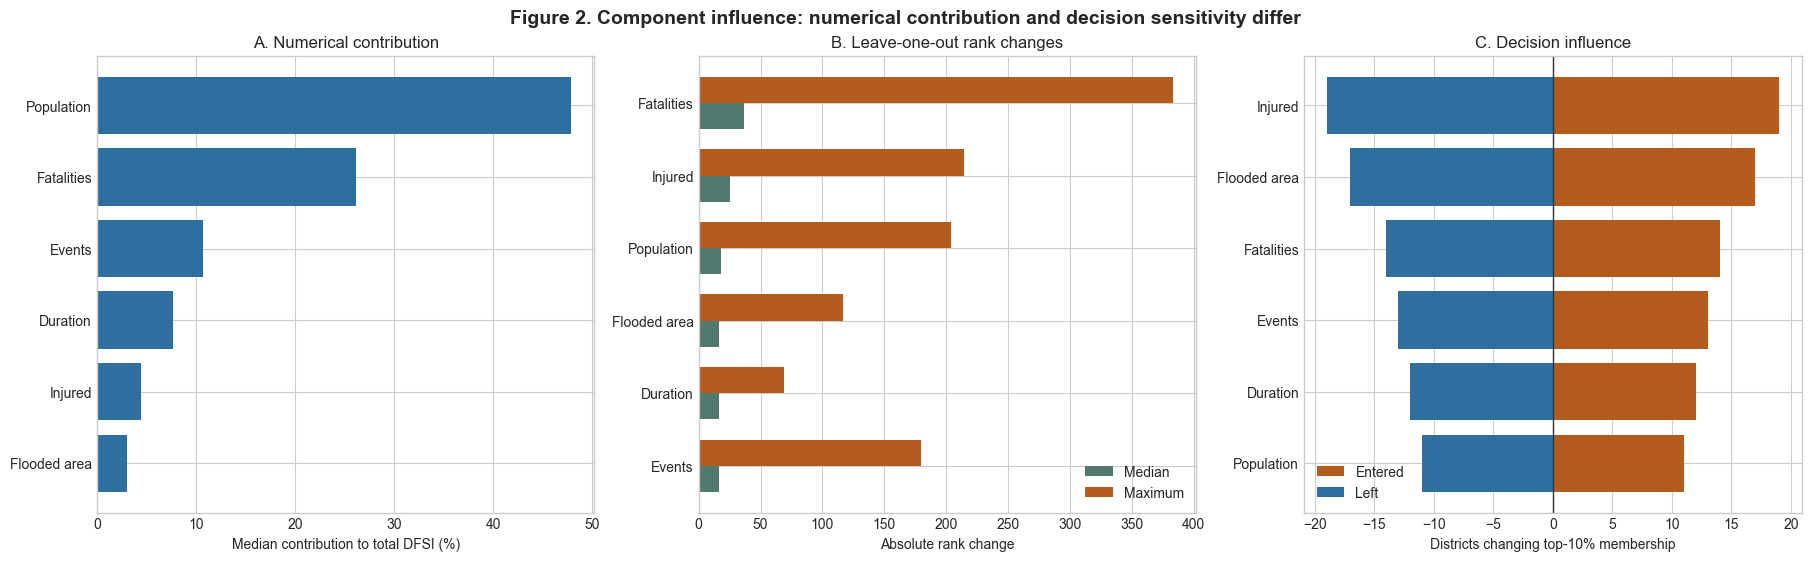

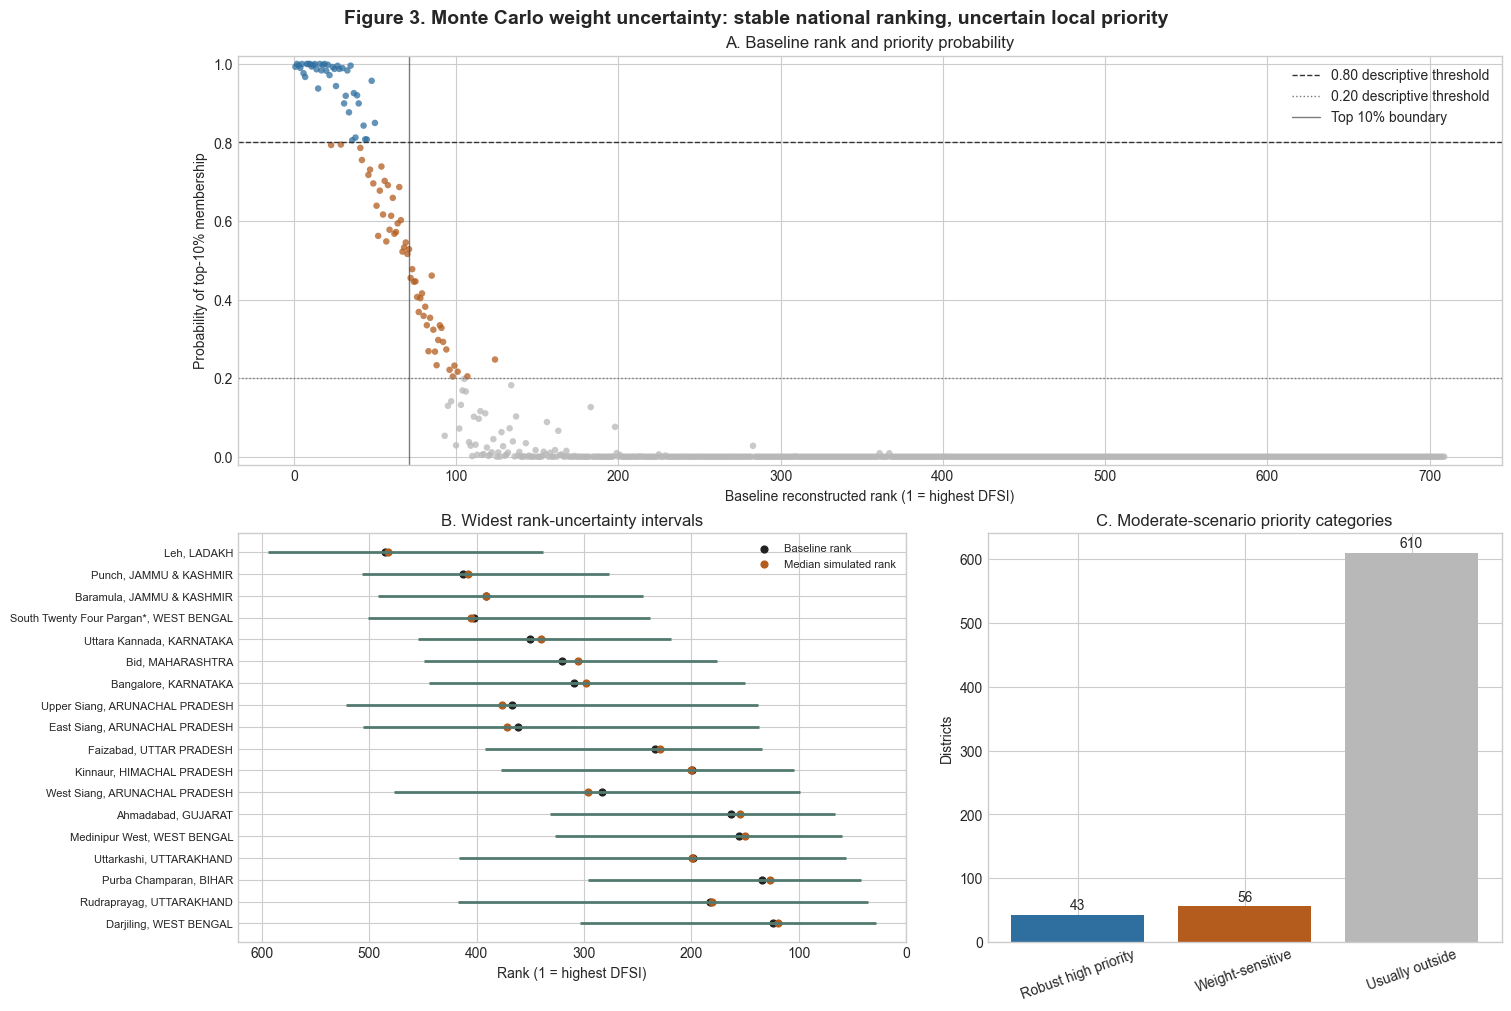

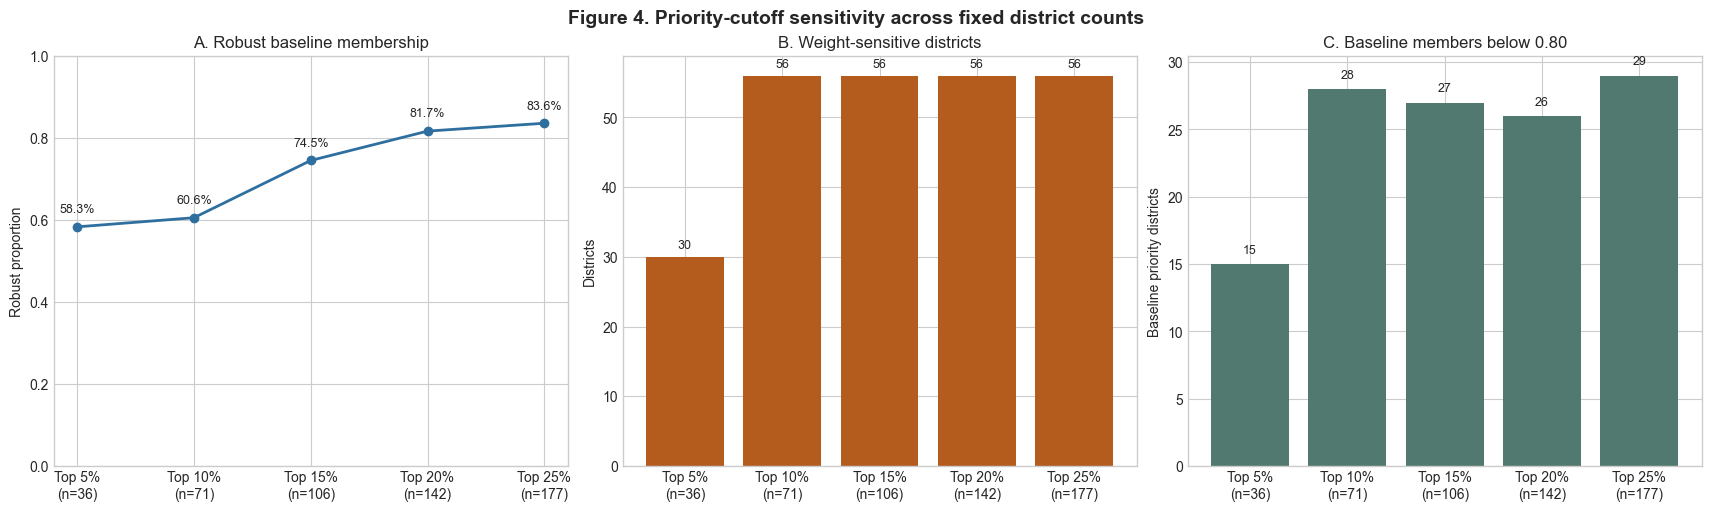

In [5]:
# Figure 1.
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
p = complete_baseline.copy()
axes[0].scatter(p['published_dfsi'], p['reconstructed_dfsi'], s=18, alpha=0.65, color='#2f6f9f', edgecolor='none')
lims = [min(p['published_dfsi'].min(), p['reconstructed_dfsi'].min()), max(p['published_dfsi'].max(), p['reconstructed_dfsi'].max())]
axes[0].plot(lims, lims, color='#333333', linestyle='--', linewidth=1)
axes[0].set_xlabel('Published DFSI'); axes[0].set_ylabel('Reconstructed DFSI'); axes[0].set_title('A. DFSI scores')
axes[0].text(0.03,0.97,f"n = 709\nSpearman = {metric_float('spearman_correlation'):.5f}\nPearson = {metric_float('pearson_correlation'):.5f}",transform=axes[0].transAxes,va='top',bbox={'boxstyle':'round,pad=0.25','facecolor':'white','alpha':0.85,'edgecolor':'#cccccc'})
axes[1].scatter(p['published_rank'], p['reconstructed_rank'], s=18, alpha=0.65, color='#52796f', edgecolor='none')
axes[1].plot([1,709],[1,709], color='#333333', linestyle='--', linewidth=1)
axes[1].invert_xaxis(); axes[1].invert_yaxis()
axes[1].set_xlabel('Published rank (1 = highest DFSI)'); axes[1].set_ylabel('Reconstructed rank (1 = highest DFSI)'); axes[1].set_title('B. District ranks')
order = ['top_25_districts','top_50_districts','top_10_percent','top_100_districts']
op = verified_overlap.set_index('group').loc[order].reset_index()
labels = ['Top 25','Top 50','Top 10%','Top 100']
axes[2].bar(labels, op['overlap_count'], color='#b35c1e')
for i,row in enumerate(op.itertuples(index=False)):
    axes[2].text(i,row.overlap_count+1.2,f'{int(row.overlap_count)}/{int(row.n_requested)}',ha='center',fontsize=9)
axes[2].set_ylim(0, max(op['n_requested'])*1.12); axes[2].set_ylabel('Overlapping districts'); axes[2].set_title('C. Priority-group overlap')
fig.suptitle('Figure 1. DFSI reproduction: strong ranking reproduction without exact numerical match', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'paper_figure_1_dfsi_reproduction.png', dpi=300, bbox_inches='tight')
plt.show()

# Figure 2.
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)
label_map = {'flood_events':'Events','mean_duration':'Duration','fatalities':'Fatalities','injured_people':'Injured','flooded_area':'Flooded area','population':'Population'}
cp = component_summary.copy(); cp['label'] = cp['component'].map(label_map); cp = cp.sort_values('median_percentage_contribution_to_total_dfsi')
axes[0].barh(cp['label'], cp['median_percentage_contribution_to_total_dfsi'], color='#2f6f9f')
axes[0].set_xlabel('Median contribution to total DFSI (%)'); axes[0].set_title('A. Numerical contribution')
lp = loo_summary.copy(); lp['label'] = lp['removed_component'].map(label_map); lp = lp.sort_values('median_absolute_rank_change')
y = np.arange(len(lp))
axes[1].barh(y-0.18, lp['median_absolute_rank_change'], height=0.36, label='Median', color='#52796f')
axes[1].barh(y+0.18, lp['maximum_absolute_rank_change'], height=0.36, label='Maximum', color='#b35c1e')
axes[1].set_yticks(y); axes[1].set_yticklabels(lp['label']); axes[1].set_xlabel('Absolute rank change'); axes[1].set_title('B. Leave-one-out rank changes'); axes[1].legend()
lt = loo_summary.copy(); lt['label'] = lt['removed_component'].map(label_map); lt = lt.sort_values('districts_entering_top_10_percent_count')
axes[2].barh(lt['label'], lt['districts_entering_top_10_percent_count'], color='#b35c1e', label='Entered')
axes[2].barh(lt['label'], -lt['districts_leaving_top_10_percent_count'], color='#2f6f9f', label='Left')
axes[2].axvline(0, color='#333333', linewidth=1); axes[2].set_xlabel('Districts changing top-10% membership'); axes[2].set_title('C. Decision influence'); axes[2].legend()
fig.suptitle('Figure 2. Component influence: numerical contribution and decision sensitivity differ', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'paper_figure_2_component_influence.png', dpi=300, bbox_inches='tight')
plt.show()

# Figure 3.
moderate = mc_district.query("scenario == 'moderate'").copy().sort_values('baseline_rank')
fig = plt.figure(figsize=(15,10), constrained_layout=True)
gs = fig.add_gridspec(2,2,width_ratios=[1.3,1.0])
ax0 = fig.add_subplot(gs[0,:]); ax1 = fig.add_subplot(gs[1,0]); ax2 = fig.add_subplot(gs[1,1])
colors = np.select([moderate['top10_probability']>=0.80, (moderate['top10_probability']>0.20)&(moderate['top10_probability']<0.80)], ['#2f6f9f','#b35c1e'], default='#b8b8b8')
ax0.scatter(moderate['baseline_rank'], moderate['top10_probability'], s=22, alpha=0.75, c=colors, edgecolor='none')
ax0.axhline(0.80,color='#333333',linestyle='--',linewidth=1,label='0.80 descriptive threshold'); ax0.axhline(0.20,color='#777777',linestyle=':',linewidth=1,label='0.20 descriptive threshold'); ax0.axvline(71,color='#444444',linewidth=1,alpha=0.7,label='Top 10% boundary')
ax0.set_xlabel('Baseline reconstructed rank (1 = highest DFSI)'); ax0.set_ylabel('Probability of top-10% membership'); ax0.set_ylim(-0.02,1.02); ax0.set_title('A. Baseline rank and priority probability'); ax0.legend(loc='upper right')
interval = moderate.sort_values('rank_p05_to_p95_interval', ascending=False).head(18).sort_values('rank_p05')
y = np.arange(len(interval))
ax1.hlines(y, interval['rank_p05'], interval['rank_p95'], color='#52796f', linewidth=2)
ax1.scatter(interval['baseline_rank'], y, color='#222222', s=24, label='Baseline rank'); ax1.scatter(interval['median_simulated_rank'], y, color='#b35c1e', s=24, label='Median simulated rank')
ax1.set_yticks(y); ax1.set_yticklabels(interval['district_name']+', '+interval['State_Name'].astype(str), fontsize=8); ax1.invert_xaxis(); ax1.set_xlabel('Rank (1 = highest DFSI)'); ax1.set_title('B. Widest rank-uncertainty intervals'); ax1.legend(fontsize=8)
cat_counts = pd.Series({'Robust high priority':int((moderate['top10_probability']>=0.80).sum()), 'Weight-sensitive':int(((moderate['top10_probability']>0.20)&(moderate['top10_probability']<0.80)).sum()), 'Usually outside':int((moderate['top10_probability']<=0.20).sum())})
ax2.bar(cat_counts.index, cat_counts.values, color=['#2f6f9f','#b35c1e','#b8b8b8'])
for i,v in enumerate(cat_counts.values): ax2.text(i,v+8,str(v),ha='center')
ax2.set_ylabel('Districts'); ax2.set_title('C. Moderate-scenario priority categories'); ax2.tick_params(axis='x', rotation=20)
fig.suptitle('Figure 3. Monte Carlo weight uncertainty: stable national ranking, uncertain local priority', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'paper_figure_3_monte_carlo_uncertainty.png', dpi=300, bbox_inches='tight')
plt.show()

# Figure 4.
cut = cutoff_summary.copy(); cut['label'] = cut['cutoff'].map({'top_5pct':'Top 5%\n(n=36)','top_10pct':'Top 10%\n(n=71)','top_15pct':'Top 15%\n(n=106)','top_20pct':'Top 20%\n(n=142)','top_25pct':'Top 25%\n(n=177)'})
fig, axes = plt.subplots(1,3,figsize=(17,5), constrained_layout=True)
axes[0].plot(cut['label'], cut['baseline_priority_robust_proportion'], marker='o', color='#2f6f9f', linewidth=2); axes[0].set_ylim(0,1); axes[0].set_ylabel('Robust proportion'); axes[0].set_title('A. Robust baseline membership')
for xval,yval in zip(cut['label'], cut['baseline_priority_robust_proportion']): axes[0].text(xval,yval+0.035,f'{yval:.1%}',ha='center',fontsize=9)
axes[1].bar(cut['label'], cut['cutoff_sensitive_districts'], color='#b35c1e'); axes[1].set_ylabel('Districts'); axes[1].set_title('B. Weight-sensitive districts')
for i,v in enumerate(cut['cutoff_sensitive_districts']): axes[1].text(i,v+1.2,str(int(v)),ha='center',fontsize=9)
axes[2].bar(cut['label'], cut['baseline_members_below_0_80_probability'], color='#52796f'); axes[2].set_ylabel('Baseline priority districts'); axes[2].set_title('C. Baseline members below 0.80')
for i,v in enumerate(cut['baseline_members_below_0_80_probability']): axes[2].text(i,v+0.8,str(int(v)),ha='center',fontsize=9)
fig.suptitle('Figure 4. Priority-cutoff sensitivity across fixed district counts', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'paper_figure_4_cutoff_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()

for fn in ['paper_figure_1_dfsi_reproduction.png','paper_figure_2_component_influence.png','paper_figure_3_monte_carlo_uncertainty.png','paper_figure_4_cutoff_sensitivity.png']:
    path = FIGURE_DIR / fn
    assert path.exists() and path.stat().st_size > 0

## Supplementary Figures

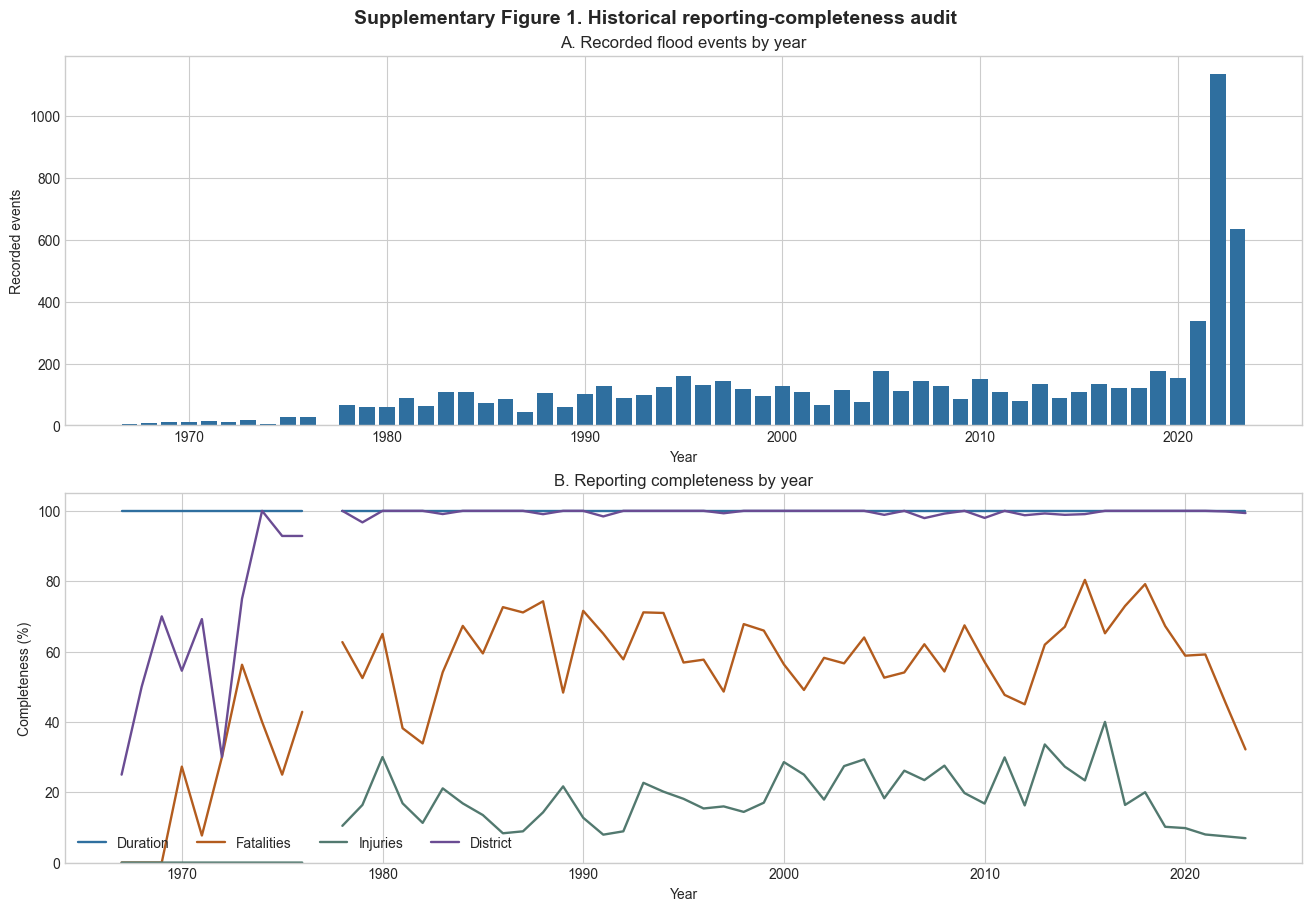

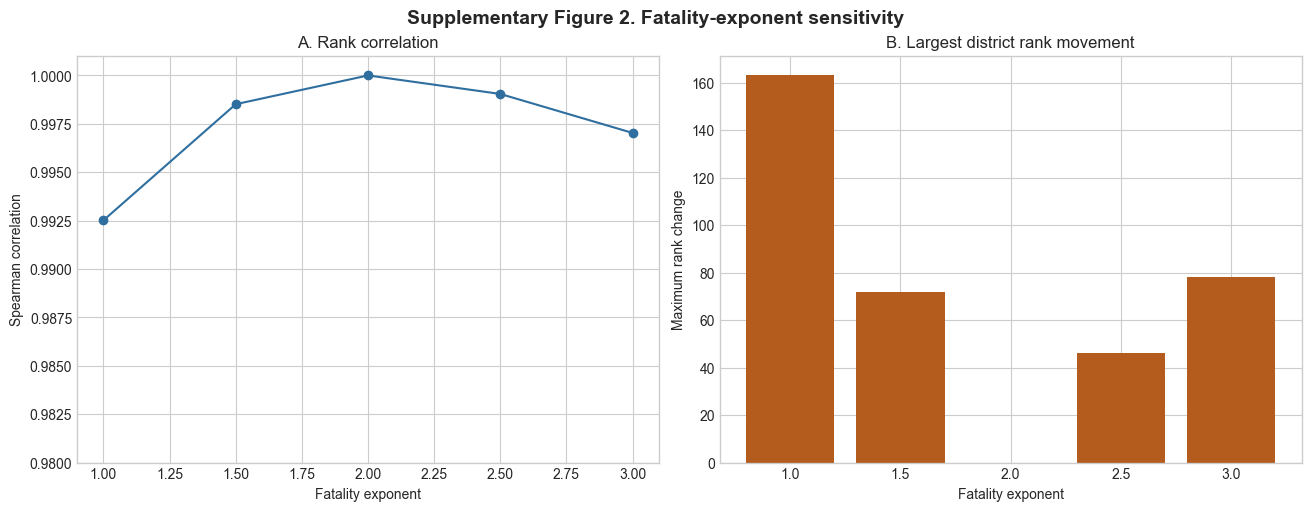

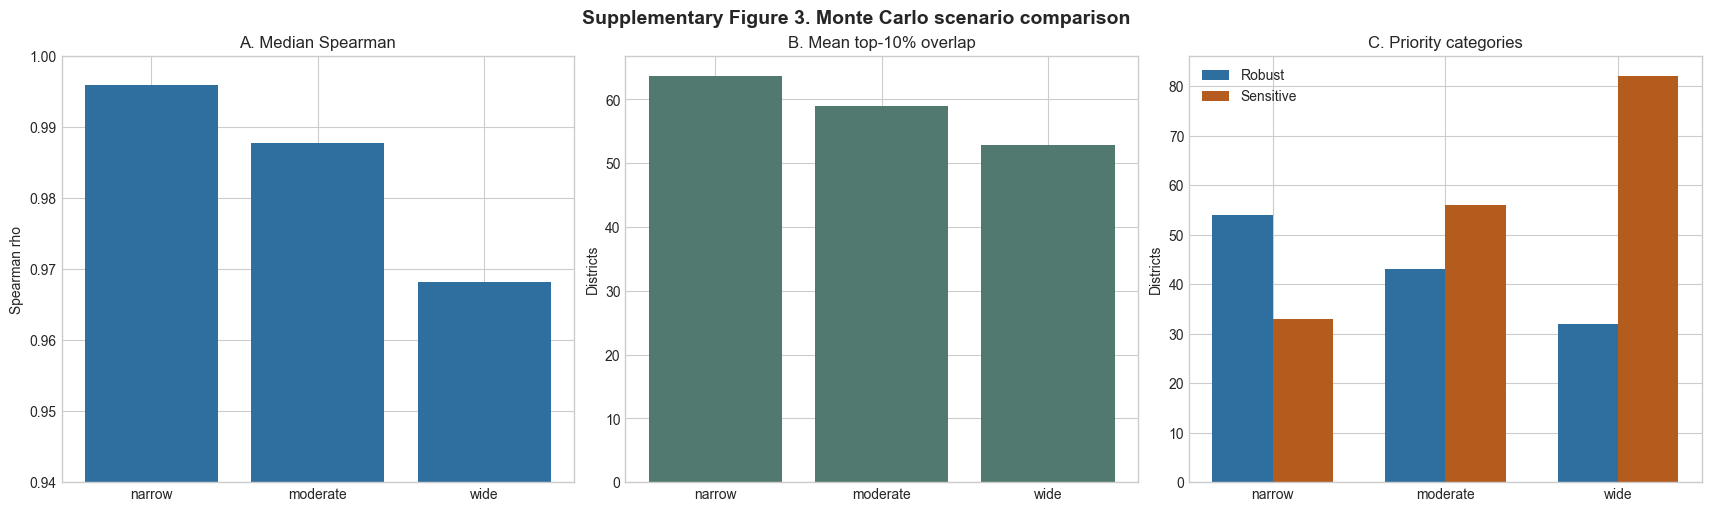

In [6]:
fig, axes = plt.subplots(2,1,figsize=(13,9), constrained_layout=True)
axes[0].bar(annual_completeness['year'], annual_completeness['recorded_flood_events'], color='#2f6f9f')
axes[0].set_title('A. Recorded flood events by year'); axes[0].set_ylabel('Recorded events'); axes[0].set_xlabel('Year')
for col,label,color in [('valid_duration_percent','Duration','#2f6f9f'),('fatalities_reported_percent','Fatalities','#b35c1e'),('injured_reported_percent','Injuries','#52796f'),('valid_district_percent','District','#6a4c93')]:
    axes[1].plot(annual_completeness['year'], annual_completeness[col], label=label, linewidth=1.7, color=color)
axes[1].set_ylim(0,105); axes[1].set_title('B. Reporting completeness by year'); axes[1].set_ylabel('Completeness (%)'); axes[1].set_xlabel('Year'); axes[1].legend(ncol=4)
fig.suptitle('Supplementary Figure 1. Historical reporting-completeness audit', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'supplementary_figure_1_reporting_completeness.png', dpi=300, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1,2,figsize=(13,5), constrained_layout=True)
axes[0].plot(fatality_summary['fatality_exponent'], fatality_summary['spearman_correlation_with_exponent_2_baseline'], marker='o', color='#2f6f9f')
axes[0].set_xlabel('Fatality exponent'); axes[0].set_ylabel('Spearman correlation'); axes[0].set_ylim(0.98,1.001); axes[0].set_title('A. Rank correlation')
axes[1].bar(fatality_summary['fatality_exponent'].astype(str), fatality_summary['maximum_rank_change'], color='#b35c1e')
axes[1].set_xlabel('Fatality exponent'); axes[1].set_ylabel('Maximum rank change'); axes[1].set_title('B. Largest district rank movement')
fig.suptitle('Supplementary Figure 2. Fatality-exponent sensitivity', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'supplementary_figure_2_fatality_exponent.png', dpi=300, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1,3,figsize=(17,5), constrained_layout=True)
mcplot = mc_summary.set_index('scenario').loc[['narrow','moderate','wide']].reset_index()
axes[0].bar(mcplot['scenario'], mcplot['median_spearman_correlation_with_baseline_rank'], color='#2f6f9f'); axes[0].set_ylim(0.94,1.0); axes[0].set_title('A. Median Spearman'); axes[0].set_ylabel('Spearman rho')
axes[1].bar(mcplot['scenario'], mcplot['mean_top10_overlap_with_baseline'], color='#52796f'); axes[1].set_title('B. Mean top-10% overlap'); axes[1].set_ylabel('Districts')
x=np.arange(len(mcplot)); width=0.35
axes[2].bar(x-width/2, mcplot['robust_high_priority_districts'], width=width, label='Robust', color='#2f6f9f')
axes[2].bar(x+width/2, mcplot['weight_sensitive_priority_districts'], width=width, label='Sensitive', color='#b35c1e')
axes[2].set_xticks(x); axes[2].set_xticklabels(mcplot['scenario']); axes[2].set_title('C. Priority categories'); axes[2].set_ylabel('Districts'); axes[2].legend()
fig.suptitle('Supplementary Figure 3. Monte Carlo scenario comparison', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'supplementary_figure_3_weight_scenarios.png', dpi=300, bbox_inches='tight')
plt.show()

for fn in ['supplementary_figure_1_reporting_completeness.png','supplementary_figure_2_fatality_exponent.png','supplementary_figure_3_weight_scenarios.png']:
    path = FIGURE_DIR / fn
    assert path.exists() and path.stat().st_size > 0

## Captions and Manuscript Scaffold

In [7]:
figure_captions = '''# Figure Captions

**Figure 1. DFSI reproduction.** Published DFSI scores and ranks are compared with the verified reconstructed DFSI for 709 complete one-to-one district records. Ranks are ordered in descending DFSI, so rank 1 represents the highest DFSI. Panel A compares scores, panel B compares ranks, and panel C reports overlap between published and reconstructed priority groups for the top 25, top 50, top 10% (71 districts) and top 100 districts. The reconstructed index strongly reproduces the published ranking but does not exactly reproduce published numerical values.

**Figure 2. Component influence.** Component term contributions and leave-one-component-out rank changes are shown for the 709 complete district records. Panel A reports median numerical contribution to reconstructed DFSI. Panels B and C report decision sensitivity after removing one component at a time. Component contributions and correlations are descriptive associations and should not be interpreted as causal effects.

**Figure 3. Monte Carlo priority uncertainty.** The primary moderate uncertainty scenario samples 10,000 weight vectors centred on the published DFSI weighting structure and evaluates top-10% priority membership among 709 complete district records. Ranks are descending, with rank 1 highest. Robust high-priority districts have top-10% probability >= 0.80, weight-sensitive districts have probability > 0.20 and < 0.80, and usually-outside districts have probability <= 0.20. The 0.20 and 0.80 values are descriptive reporting thresholds, not universal policy standards. High national rank correlation can coexist with unstable district membership.

**Figure 4. Priority-cutoff sensitivity.** The moderate Monte Carlo scenario is evaluated under fixed priority cutoffs of top 5% (36 districts), top 10% (71), top 15% (106), top 20% (142) and top 25% (177). The figure reports the share of baseline priority districts that are robust, the number of weight-sensitive districts, and the number of baseline priority districts below 0.80 membership probability. Results test whether the paper's priority-instability conclusion depends on the top-10% threshold.

**Supplementary Figure 1. Historical reporting completeness.** Annual recorded flood-event counts and reporting completeness are shown for the India Flood Inventory audit period. Recorded event counts are reporting volume and should not be interpreted as physical flood-frequency trends.

**Supplementary Figure 2. Fatality-exponent sensitivity.** Alternative fatality exponents are compared with the correctly reconstructed exponent-2 DFSI baseline for 709 complete district records. The figure reports rank correlation and maximum district rank movement.

**Supplementary Figure 3. Monte Carlo scenario comparison.** Narrow, moderate and wide uncertainty scenarios are compared using saved Monte Carlo outputs. The moderate scenario is the primary analysis because it remains centred on the published weighting structure while allowing meaningful methodological variation.
'''
(PAPER_DIR / 'figure_captions.md').write_text(figure_captions, encoding='utf-8')

table_captions = '''# Table Captions

**Table 1. DFSI reproduction summary.** Summary of the verified DFSI reproduction using one-to-one comparison records. The table reports sample size, incomplete records retained without imputation, published and reconstructed DFSI ranges, Pearson and Spearman correlations, numerical differences, rank differences and priority-group overlaps. Ranks are descending, so rank 1 is the highest DFSI.

**Table 2. Component and weight sensitivity.** Consolidated summary of component median contributions, leave-one-component-out sensitivity and fatality-exponent sensitivity using the 709 complete district records. Component correlations and contributions are descriptive and do not imply causal importance.

**Table 3. Monte Carlo and cutoff sensitivity summary.** Summary of narrow, moderate and wide Monte Carlo uncertainty scenarios and the priority-cutoff sensitivity analysis. The moderate scenario is the primary analysis. Robust high-priority districts have membership probability >= 0.80, weight-sensitive districts have probability > 0.20 and < 0.80, and usually-outside districts have probability <= 0.20. These thresholds are descriptive reporting thresholds. High rank correlation can coexist with unstable district-level priority membership.

**Supplementary district-level tables.** District-level uncertainty, rank movement and cutoff-membership results are retained in machine-readable CSV files under `outputs/tables/` rather than placed in the main manuscript tables.
'''
(PAPER_DIR / 'table_captions.md').write_text(table_captions, encoding='utf-8')

values = {
    'one_to_one': metric_int('one_to_one_comparison_rows'),
    'complete': metric_int('complete_comparison_rows'),
    'incomplete': metric_int('incomplete_records_preserved'),
    'recon_min': complete_baseline['reconstructed_dfsi'].min(),
    'recon_max': complete_baseline['reconstructed_dfsi'].max(),
    'published_min': complete_baseline['published_dfsi'].min(),
    'published_max': complete_baseline['published_dfsi'].max(),
    'spearman': metric_float('spearman_correlation'),
    'pearson': metric_float('pearson_correlation'),
    'median_num_diff': metric_float('median_absolute_numerical_difference'),
    'median_rank_diff': metric_float('median_absolute_rank_difference'),
    'max_rank_diff': metric_float('maximum_absolute_rank_difference'),
    'overlap25': int(overlap('top_25_districts','overlap_count')),
    'overlap50': int(overlap('top_50_districts','overlap_count')),
    'overlap10pct': int(overlap('top_10_percent','overlap_count')),
    'overlap100': int(overlap('top_100_districts','overlap_count')),
    'pop_contrib': component('population','median_percentage_contribution_to_total_dfsi'),
    'fat_contrib': component('fatalities','median_percentage_contribution_to_total_dfsi'),
    'event_contrib': component('flood_events','median_percentage_contribution_to_total_dfsi'),
    'loo_fat_median': loo('fatalities','median_absolute_rank_change'),
    'loo_fat_max': loo('fatalities','maximum_absolute_rank_change'),
    'loo_inj_enter': loo('injured_people','districts_entering_top_10_percent_count'),
    'loo_inj_leave': loo('injured_people','districts_leaving_top_10_percent_count'),
    'loo_min_rho': loo_summary['spearman_correlation_with_complete_baseline_index'].min(),
    'fat1_rho': fat(1.0,'spearman_correlation_with_exponent_2_baseline'),
    'fat1_median': fat(1.0,'median_absolute_rank_change'),
    'fat1_max': fat(1.0,'maximum_rank_change'),
    'fat1_overlap': fat(1.0,'top_10_percent_overlap_count'),
    'mc_sims': mc('moderate','simulations'),
    'mc_conc': mc('moderate','concentration'),
    'mc_rho': mc('moderate','median_spearman_correlation_with_baseline_rank'),
    'mc_robust': mc('moderate','robust_high_priority_districts'),
    'mc_sensitive': mc('moderate','weight_sensitive_priority_districts'),
    'mc_usually': int(mod['top10_probability'].le(0.20).sum()),
    'mc_below80': int((mod['baseline_top10'] & mod['top10_probability'].lt(0.80)).sum()),
    'cut5': cutoff('top_5pct','baseline_priority_robust_proportion'),
    'cut10': cutoff('top_10pct','baseline_priority_robust_proportion'),
    'cut15': cutoff('top_15pct','baseline_priority_robust_proportion'),
    'cut20': cutoff('top_20pct','baseline_priority_robust_proportion'),
    'cut25': cutoff('top_25pct','baseline_priority_robust_proportion'),
    'cut_sensitive_max': cutoff_summary['cutoff_sensitive_districts'].max(),
    'start_year': window_completeness['start_year'].min(),
    'end_year': window_completeness['end_year'].max(),
}

manuscript = '''# Robust National Rankings, Uncertain Local Priorities:\nA Sensitivity Audit of India’s District Flood Severity Index

# Abstract

Structured abstract placeholder.

- **Background:** Placeholder.
- **Objective:** Placeholder.
- **Methods:** Placeholder.
- **Results:** Placeholder.
- **Conclusions:** Placeholder.

# 1. Introduction

- Motivate district-level flood-risk prioritisation in India.
- Introduce index-based prioritisation and the need for reproducible audits.
- Distinguish national ranking reproduction from local decision stability.
- State the study objective: evaluate robustness of district prioritisation under defensible methodological alternatives.

# 2. Data and Methods

## 2.1 Data sources

The analysis used the released DFSI and component datasets preserved in the project repository, including the published DFSI table, district-level flood-impact data, district-level flooded-area data and the India Flood Inventory. Raw files were treated as immutable inputs. Processed comparison records and audit outputs from the verified reproduction workflow were used for consolidation. The final verified baseline contained {one_to_one} one-to-one comparison records, of which {complete} were complete and {incomplete} were retained as incomplete without imputation (Claims R01-R03).

## 2.2 DFSI reproduction

The published DFSI was approximately reproduced using the released component data and the corrected additive log-space expression. The reconstructed index was compared with the published DFSI score rather than with the published rank. Ranks were ordered in descending DFSI, so rank 1 indicates the highest score. Reproduction was evaluated using Pearson correlation, Spearman rank correlation, absolute numerical differences, absolute rank differences and overlap of published and reconstructed high-priority groups. Exact numerical reproduction was not claimed.

## 2.3 Fatality-exponent sensitivity

The published index gives fatalities an exponent of 2. To evaluate sensitivity to this design choice, alternative indices were calculated using fatality exponents of 1.0, 1.5, 2.0, 2.5 and 3.0 while leaving all other component transformations unchanged. Each variant was compared with the correctly reconstructed exponent-2 baseline, not with the published DFSI, so that the experiment isolated the fatality-weighting choice.

## 2.4 Leave-one-component-out analysis

Six leave-one-component-out variants were constructed by removing one DFSI component at a time from the reconstructed baseline. The analysis recalculated district ranks after each removal and summarized rank correlation, median and maximum absolute rank change, top-group overlap and changes in top-10% membership. Component correlations and term contributions were interpreted as descriptive diagnostics rather than causal effects.

## 2.5 Monte Carlo weight uncertainty

Monte Carlo weight uncertainty was evaluated using unweighted log terms for flood-event frequency, mean duration, fatalities, injured people, flooded area and population. Weight vectors were sampled in prior verified analysis from Dirichlet distributions centred on the published weight proportions. The present manuscript treats the moderate uncertainty scenario as the primary analysis because it remains centred on the published weighting structure while permitting meaningful methodological variation (Claims MC01-MC02). Districts were categorized using top-10% membership probabilities: robust high-priority districts had probability >= 0.80, weight-sensitive districts had probability > 0.20 and < 0.80, and usually-outside districts had probability <= 0.20. The 0.20 and 0.80 values are descriptive reporting thresholds, not universal policy standards.

## 2.6 Priority-cutoff sensitivity

Priority-cutoff sensitivity tested whether conclusions depended on selecting the top 10% as the policy-priority group. The saved moderate-scenario Monte Carlo outputs were evaluated under fixed cutoffs of top 5%, top 10%, top 15%, top 20% and top 25%, corresponding to 36, 71, 106, 142 and 177 districts (Claims P_top_5pct_count-P_top_25pct_count). The analysis reported robust membership, weight-sensitive membership and baseline priority districts with membership probability below 0.80.

## 2.7 Historical reporting-completeness audit

The India Flood Inventory was audited for historical reporting volume and completeness over the period {start_year}-{end_year} (Claims T01-T02). The audit evaluated whether temporal DFSI sensitivity analysis could be conducted without confusing changing reporting completeness with changing flood risk. Recorded event counts were treated as reporting volume and were not interpreted as physical flood-frequency trends.

## 2.8 Evaluation metrics and reporting thresholds

The study reports Pearson correlation for numerical agreement and Spearman correlation for ranking agreement. Rank differences are absolute differences in descending ranks. Priority-group overlap is reported as the number of districts common to two high-priority sets. Monte Carlo priority categories use the descriptive thresholds 0.20 and 0.80. These thresholds support transparent reporting but are not proposed as universal policy standards.

# 3. Results

## 3.1 Reproduction of the published DFSI

The verified reproduction used {complete} complete district records from {one_to_one} one-to-one baseline records, while preserving {incomplete} incomplete records without imputation (Claims R01-R03). The reconstructed DFSI ranged from {recon_min:.4f} to {recon_max:.4f}, while the published DFSI among complete records ranged from {published_min:.4f} to {published_max:.4f} (Claims R09-R12). The reconstructed index strongly reproduced the published ranking, with Spearman correlation {spearman:.5f} and Pearson correlation {pearson:.5f} (Claims R04-R05). However, exact numerical reproduction was not achieved: the median absolute numerical difference was {median_num_diff:.5f}, the median absolute rank difference was {median_rank_diff:.0f} positions and the maximum absolute rank difference was {max_rank_diff:.0f} positions (Claims R06-R08). Published-versus-reconstructed overlap was {overlap25} of 25 districts, {overlap50} of 50, {overlap10pct} of 71 and {overlap100} of 100 (Claims R13-R16).

## 3.2 Component influence and leave-one-out sensitivity

The largest median numerical contribution came from population ({pop_contrib:.1f}%), followed by fatalities ({fat_contrib:.1f}%) and flood-event frequency ({event_contrib:.1f}%) (Claims C01-C06). These values describe the arithmetic composition of the reconstructed score and should not be interpreted as causal importance. Leave-one-component-out analysis showed that removing fatalities produced a median absolute rank change of {loo_fat_median:.0f} positions and a maximum absolute rank change of {loo_fat_max:.0f} positions (Claims L01-L02). Removing injured people produced the largest top-10% membership turnover, with {loo_inj_enter:.0f} districts entering and {loo_inj_leave:.0f} leaving the group (Claims L03-L04). All leave-one-component-out variants retained Spearman correlations above {loo_min_rho:.2f}, indicating that high national rank correlation can coexist with substantial district-level movement (Claim L05).

Fatality-exponent sensitivity produced high rank correlations with the reconstructed exponent-2 baseline, but individual district movements remained nontrivial. Reducing the exponent to 1.0 gave Spearman correlation {fat1_rho:.4f}, median absolute rank change {fat1_median:.0f}, maximum rank change {fat1_max:.0f} and top-10% overlap {fat1_overlap:.0f} of 71 districts (Claims F1_0_rho-F1_0_top10).

## 3.3 Monte Carlo uncertainty in district prioritisation

In the primary moderate uncertainty scenario, {mc_sims:.0f} saved Monte Carlo weight vectors were evaluated for {complete} complete districts (Claims MC01-MC02). The median Spearman correlation with the baseline ranking was {mc_rho:.4f}, but top-priority membership remained sensitive (Claim MC_moderate_rho). The scenario identified {mc_robust:.0f} robust high-priority districts, {mc_sensitive:.0f} weight-sensitive districts and {mc_usually:.0f} usually-outside districts (Claims MC_moderate_robust, MC_moderate_sensitive and MC04). Among baseline top-10% districts, {mc_below80:.0f} had less than 0.80 probability of remaining in the top 10% (Claim MC03). Thus, national ranking stability did not guarantee district-level decision stability.

## 3.4 Sensitivity to the policy-priority cutoff

Priority instability persisted across all five priority thresholds examined (Claim P02). The proportion of baseline priority districts classified as robust was {cut5:.1%} for the top 5%, {cut10:.1%} for the top 10%, {cut15:.1%} for the top 15%, {cut20:.1%} for the top 20% and {cut25:.1%} for the top 25% (Claims P_top_5pct_robust_share-P_top_25pct_robust_share). The largest number of weight-sensitive districts was {cut_sensitive_max:.0f}, observed under the top-10%, top-15%, top-20% and top-25% thresholds (Claim P01). These results indicate that the central conclusion does not depend on using the top-10% threshold.

## 3.5 Limitations of temporal comparison

The reporting-completeness audit found that recorded flood-event volume changed substantially over time and that reporting completeness also changed substantially (Claims T03-T04). A complete period-specific DFSI could not be reconstructed from the event inventory alone (Claim T05), because flooded-area percentage and population were not available as period-specific components and because historical reporting coverage was uneven. Event-derived temporal sensitivity analysis may be technically possible with caveats (Claim T06), but it would not be equivalent to the published DFSI and should not be interpreted as a direct trend in physical flood risk.

# 4. Discussion

- Interpret strong national rank reproduction alongside non-exact numerical reproduction.
- Discuss why policy decisions based on top-priority membership require more than rank correlation.
- Discuss component-weight uncertainty as a transparent robustness problem.
- Discuss implications for district prioritisation and communication of uncertainty.
- Discuss limitations of static population/flooded-area components and historical reporting completeness.

# 5. Conclusion

- The released datasets approximately reproduce the published DFSI ranking.
- District-level priority membership is sensitive to reasonable methodological alternatives.
- Robust prioritisation should report priority probabilities and cutoff sensitivity, not only national rank correlations.
- Temporal claims require explicit reporting-completeness caveats.

# Data and Code Availability

Placeholder. Data and analysis code availability statement to be completed after repository and dataset citation details are finalized.

# References

- Original DFSI paper placeholder.
- Zenodo dataset placeholder.
'''.format(**values)
(PAPER_DIR / 'manuscript.md').write_text(manuscript, encoding='utf-8')
print('Wrote captions and manuscript scaffold.')

Wrote captions and manuscript scaffold.


## Output Manifest and Final Validation

In [8]:
manifest_rows = [
    ['paper/results_claims_audit.csv','main','notebooks/09_paper_ready_outputs.ipynb','multiple verified output CSVs','All results sections','created','Claim IDs unique; headline assertions passed.'],
    ['outputs/figures/paper_figure_1_dfsi_reproduction.png','main','notebooks/09_paper_ready_outputs.ipynb','dfsi_verified_comparison; dfsi_verified_top_group_overlap','3.1','created','Uses complete n=709 records; outliers not hidden.'],
    ['outputs/figures/paper_figure_2_component_influence.png','main','notebooks/09_paper_ready_outputs.ipynb','dfsi_component_contribution_summary; dfsi_leave_one_out_summary','3.2','created','Distinguishes numerical contribution from decision influence.'],
    ['outputs/figures/paper_figure_3_monte_carlo_uncertainty.png','main','notebooks/09_paper_ready_outputs.ipynb','dfsi_monte_carlo_district_uncertainty','3.3','created','Moderate scenario only; thresholds marked.'],
    ['outputs/figures/paper_figure_4_cutoff_sensitivity.png','main','notebooks/09_paper_ready_outputs.ipynb','dfsi_cutoff_sensitivity_summary','3.4','created','Uses fixed cutoff counts from notebook 08.'],
    ['outputs/figures/supplementary_figure_1_reporting_completeness.png','supplementary','notebooks/09_paper_ready_outputs.ipynb','flood_inventory_annual_completeness','3.5','created','Reporting volume/completeness; no physical trend claim.'],
    ['outputs/figures/supplementary_figure_2_fatality_exponent.png','supplementary','notebooks/09_paper_ready_outputs.ipynb','fatality_exponent_summary','3.2','created','Compares against reconstructed exponent-2 baseline.'],
    ['outputs/figures/supplementary_figure_3_weight_scenarios.png','supplementary','notebooks/09_paper_ready_outputs.ipynb','dfsi_monte_carlo_scenario_summary','3.3','created','Compares narrow, moderate and wide scenarios.'],
    ['paper/table_1_reproduction_summary.csv','main','notebooks/09_paper_ready_outputs.ipynb','dfsi_verified_discrepancy_summary; dfsi_verified_top_group_overlap','3.1','created','Source claim IDs included.'],
    ['paper/table_2_component_and_weight_sensitivity.csv','main','notebooks/09_paper_ready_outputs.ipynb','dfsi_component_contribution_summary; dfsi_leave_one_out_summary; fatality_exponent_summary','3.2','created','Long-format summary avoids district-level table bulk.'],
    ['paper/table_3_monte_carlo_and_cutoff_summary.csv','main','notebooks/09_paper_ready_outputs.ipynb','dfsi_monte_carlo_scenario_summary; dfsi_cutoff_sensitivity_summary','3.3; 3.4','created','Includes scenario and cutoff summaries.'],
    ['paper/figure_captions.md','main','notebooks/09_paper_ready_outputs.ipynb','paper/results_claims_audit.csv','Figures','created','Explains sample, ranks, thresholds and primary scenario.'],
    ['paper/table_captions.md','main','notebooks/09_paper_ready_outputs.ipynb','paper/results_claims_audit.csv','Tables','created','Explains categories and reporting thresholds.'],
    ['paper/manuscript.md','main','notebooks/09_paper_ready_outputs.ipynb','paper/results_claims_audit.csv','Full scaffold','created','Numerical statements cite claim IDs; implementation error omitted.'],
]
manifest = pd.DataFrame(manifest_rows, columns=['output_name','main_or_supplementary','source_notebook','source_table','manuscript_section','status','validation_notes'])
manifest.to_csv(PAPER_DIR / 'paper_output_manifest.csv', index=False)

expected = [PROJECT_ROOT / row[0] for row in manifest_rows]
for path in expected:
    assert path.exists() and path.stat().st_size > 0, path
written_claims = pd.read_csv(PAPER_DIR / 'results_claims_audit.csv')
assert written_claims['claim_id'].is_unique
written_table1 = pd.read_csv(PAPER_DIR / 'table_1_reproduction_summary.csv')
assert int(written_table1.loc[written_table1['metric'].eq('complete_comparison_records'),'value'].iloc[0]) == 709
written_table3 = pd.read_csv(PAPER_DIR / 'table_3_monte_carlo_and_cutoff_summary.csv')
moderate_table3 = written_table3.loc[(written_table3['analysis_type'].eq('monte_carlo_weight_uncertainty')) & (written_table3['item'].eq('moderate'))].iloc[0]
assert int(moderate_table3['robust_priority_districts']) == 43
assert int(moderate_table3['sensitive_priority_districts']) == 56
RAW_HASHES_AFTER = {path.name: sha256_file(path) for path in sorted(RAW_DIR.glob('*.csv'))}
assert RAW_HASHES_BEFORE == RAW_HASHES_AFTER, 'data/raw changed during paper-ready consolidation.'

print('Paper-ready output validation passed.')
for path in expected:
    print(f'- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)')

Paper-ready output validation passed.
- paper/results_claims_audit.csv (25,037 bytes)
- outputs/figures/paper_figure_1_dfsi_reproduction.png (668,013 bytes)
- outputs/figures/paper_figure_2_component_influence.png (211,700 bytes)
- outputs/figures/paper_figure_3_monte_carlo_uncertainty.png (565,238 bytes)
- outputs/figures/paper_figure_4_cutoff_sensitivity.png (218,286 bytes)
- outputs/figures/supplementary_figure_1_reporting_completeness.png (401,080 bytes)
- outputs/figures/supplementary_figure_2_fatality_exponent.png (192,369 bytes)
- outputs/figures/supplementary_figure_3_weight_scenarios.png (166,632 bytes)
- paper/table_1_reproduction_summary.csv (1,141 bytes)
- paper/table_2_component_and_weight_sensitivity.csv (1,524 bytes)
- paper/table_3_monte_carlo_and_cutoff_summary.csv (1,366 bytes)
- paper/figure_captions.md (3,040 bytes)
- paper/table_captions.md (1,501 bytes)
- paper/manuscript.md (10,446 bytes)
